# 40 · 교사·학생과 stop-gradient

📎 **이번 질문** · 다른 뷰의 표현을 맞히되 정답을 만드는 모델도 함께 바뀐다면 어떻게 학습할까요?

준비물: 13 계산 그래프, [38 변형](38_augmentations.ipynb), [39 대조학습](39_contrastive_infonce.ipynb), 03·04 미분·Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 과일의 상태와 촬영 조건을 단순화한 합성 자료로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. stop-gradient는 값을 유지하고 지정한 역전파 경로만 끊습니다.
2. online encoder·predictor는 손실로, target encoder는 optimizer 뒤 EMA로 갱신합니다.
3. 예측 손실과 표현 분산·샘플 구분·독립 probe를 함께 읽어 붕괴를 진단합니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/teacher_student_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.teacher_student_plots import plot_panels,plot_curves,plot_points
setup_plots()

'Arial Unicode MS'

## 🔑 1. 타깃의 값은 쓰고 미분 경로는 멈춥니다

**이 절에서 가져갈 것:** stop-gradient는 타깃 숫자를 지우는 것이 아니라 이번 미분에서 상수로 취급하는 규칙입니다.

같은 과일의 다른 촬영에서 나온 특징을 맞혀 봅니다. 예측 p와 타깃 t가 같아지도록 하지만 이번 갱신에서는 예측 쪽만 움직입니다.

> **용어**
> - **학생 또는 online 모델**은 손실의 기울기로 갱신하는 모델입니다.
> - **교사 또는 target 모델**은 맞혀야 할 특징을 계산하는 모델입니다. 여기서 정답 라벨을 아는 사전 학습 교사가 아닙니다.
> - **stop-gradient(sg)**는 forward 값은 그대로 두고 해당 경로의 backward를0으로 정하는 연산입니다.

스칼라 $L=\frac12(p-\mathrm{sg}(t))^2$에서 $d_p=p-t$, 학습 규약상 $d_t=0$입니다. 일반 수치 함수 $\frac12(p-t)^2$를 t에 대해 다시 계산한 수치미분은 $t-p$이므로 다릅니다. **stop-gradient의 확인은 t를 한 번 계산해 고정한 목적을 p·online 파라미터에 대해 미분**하는 방식입니다.

표현 $P,T:(N,D)$는 행별 $u=p/\sqrt{\|p\|^2+10^{-8}}$, $v=t/\sqrt{\|t\|^2+10^{-8}}$로 정규화합니다. $L=\frac1{2N}\sum_i\|u_i-\mathrm{sg}(v_i)\|^2$, $d_u=(u-v)/N$, $d_p=[d_u-u(u^Td_u)]/r$입니다. epsilon 때문에 정확한 단위벡터가 아닌 평활화한 정규화입니다.

> **코드** · NumPy에 자동 미분은 없습니다. `alignment`가 dP만 반환하고 target backward를 호출하지 않는 것으로 차단을 구현합니다. `keepdims=True`는 행별 길이를 (N,1)로 남깁니다.

In [2]:
scalar=np.array([[2.,1.]])
residual=scalar[:,0:1]-scalar[:,1:2]
scalar_paths=np.column_stack([.5*residual[:,0]**2,residual[:,0],np.zeros(1)])
small_p=np.array([[3.,4.],[0.,2.]])
small_t=np.array([[0.,5.],[2.,0.]])
pu=small_p/np.sqrt((small_p**2).sum(axis=1,keepdims=True)+1e-8)
tu=small_t/np.sqrt((small_t**2).sum(axis=1,keepdims=True)+1e-8)
row_losses=.5*((pu-tu)**2).sum(axis=1,keepdims=True)

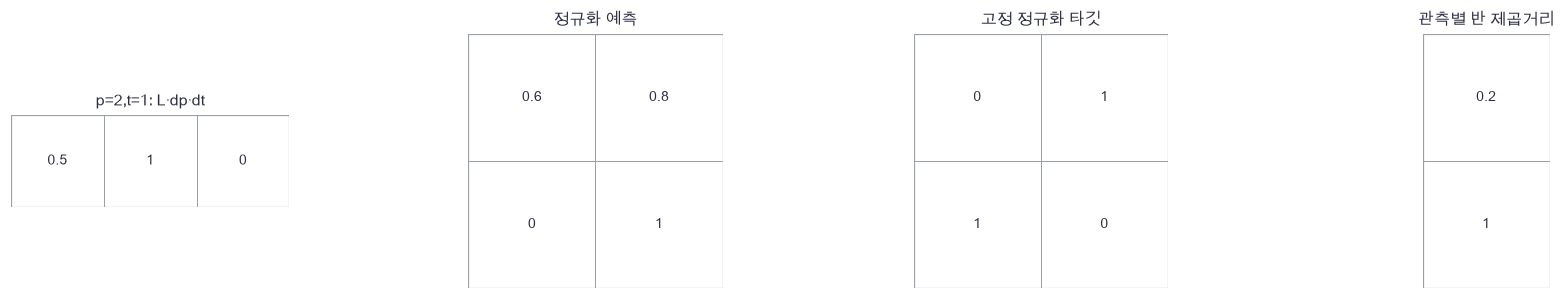

In [3]:
plot_panels([scalar_paths,pu,tu,row_losses],['p=2,t=1: L·dp·dt','정규화 예측','고정 정규화 타깃','관측별 반 제곱거리'])

🔍 **확인** · 스칼라 타깃값1은 손실과 dp 계산에 계속 쓰입니다. 오른쪽의 두 관측 손실을 평균하며 특징 수 D로 다시 나누지 않습니다.

In [4]:
def normalize_rows(H,eps=1e-8):
    """평활화한 행 정규화. H:(N,D) → U=H/sqrt(sum(H²)+eps), r:(N,1)."""
    r=np.sqrt((H**2).sum(axis=1,keepdims=True)+eps)
    return H/r,r

In [5]:
def alignment(P,T):
    """고정 target T와 정규화 예측의 반 제곱거리. → loss,dP만 반환합니다."""
    U,r=normalize_rows(P)
    V,_=normalize_rows(T)
    difference=U-V
    dU=difference/len(P)
    dP=(dU-U*(dU*U).sum(axis=1,keepdims=True))/r
    return .5*np.mean((difference**2).sum(axis=1)),dP

In [6]:
# 쓰는 것: pu (1절) · small_p (1절) · small_t (1절) · tu (1절)
hand=.5*((.6-0)**2+(.8-1)**2+1**2+(-1)**2)/2
loop_total=0.
for i in range(2):
    for j in range(2):
        loop_total+=(pu[i,j]-tu[i,j])**2/4
value,_=alignment(small_p,small_t)
np.testing.assert_allclose(value,hand,atol=1e-8)  # 검산: 두 관측 손계산 평균
np.testing.assert_allclose(value,loop_total)  # 검산: 반복문 = 벡터화
print('손계산·반복문·벡터화와 손실 분모를 확인했습니다.')

손계산·반복문·벡터화와 손실 분모를 확인했습니다.


### ✏️ 연습 1 · 고정 타깃의 예측 기울기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

정규화 전 단순 반 제곱거리의 dP를 계산하세요. T는 고정 배열입니다.

In [7]:
def exercise_stopped_residual(P,T):
    """정규화 전 단순 반 제곱거리의 dP를 계산하세요. T는 고정 배열입니다."""

    ### 구현할 내용: 정규화 전 단순 반 제곱거리의 dP를 계산하세요. T는 고정 배열입니다.
    raise NotImplementedError
    return dP

In [8]:
def check_stopped_residual(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[3.,1.],[2.,0.]]),np.array([[1.,1.],[0.,2.]])),[[1.,0.],[1.,-1.]])  # 검산: N=2 평균
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_stopped_residual,exercise_stopped_residual,hint="정규화 전 단순 반 제곱거리의 dP를 계산하세요. T는 고정 배열입니다.")

☐ exercise_stopped_residual: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정규화 전 단순 반 제곱거리의 dP를 계산하세요. T는 고정 배열입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dP = (P-T)/len(P)
```

</details>

## 🔑 2. 예측기와 학생의 모든 경로를 연결합니다

**이 절에서 가져갈 것:** predictor까지 포함한 online 전체 미분과 teacher의 갱신을 구분합니다.

학생은 사진에서 표현을 만들고, 작은 예측기를 거쳐 다른 뷰의 교사 표현을 맞힙니다. 교사에는 예측기가 없습니다.

> **용어** · **encoder**는 입력을 특징으로 바꾸는 함수입니다. **predictor**는 학생 특징을 교사 특징 공간으로 보내는 학습 가능한 함수입니다. 여기서는 선형 $P=ZQ+d$입니다.

$X:(N,4)$, $H=\tanh(XW+b):(N,F)$, $Z=HV+c:(N,D)$, $P=ZQ+d:(N,D)$입니다. 교사도 같은 encoder 구조를 쓰되 별도 파라미터 $\xi$를 가집니다. $d_Q=Z^Td_P$, $d_d=\sum d_P$, $d_Z=d_PQ^T$를 계산한 뒤 $d_A=(d_ZV^T)\odot(1-H^2)$, $d_W=X^Td_A$, $d_b=\sum d_A$, $d_V=H^Td_Z$, $d_c=\sum d_Z$, $d_X=d_AW^T$입니다.

[A,B]의 online 예측에 [B,A]의 teacher 표현을 대응시켜 양방향을 평균합니다. 두 방향 모두 teacher가 만든 값을 한 번 고정한 뒤 online만 미분합니다.

> **코드** · `p['W']` 같은 사전은 이름별 배열을 저장합니다. `.copy()`로 사본을 만들어 공유 메모리로 인한 의도하지 않은 변경을 막습니다. `concatenate(...,axis=0)`는 두 뷰를 행 방향으로 붙입니다.

In [9]:
demo_x=np.array([[1.,0.,.5,-.5],[0.,1.,-.5,.5]])
demo_h=np.tanh(demo_x@np.array([[.2,0.],[0.,.2],[.1,.1],[-.1,.1]]))
demo_z=demo_h@np.array([[1.,.2],[-.1,1.]])
demo_pred=demo_z@np.array([[.8,.2],[.1,.9]])

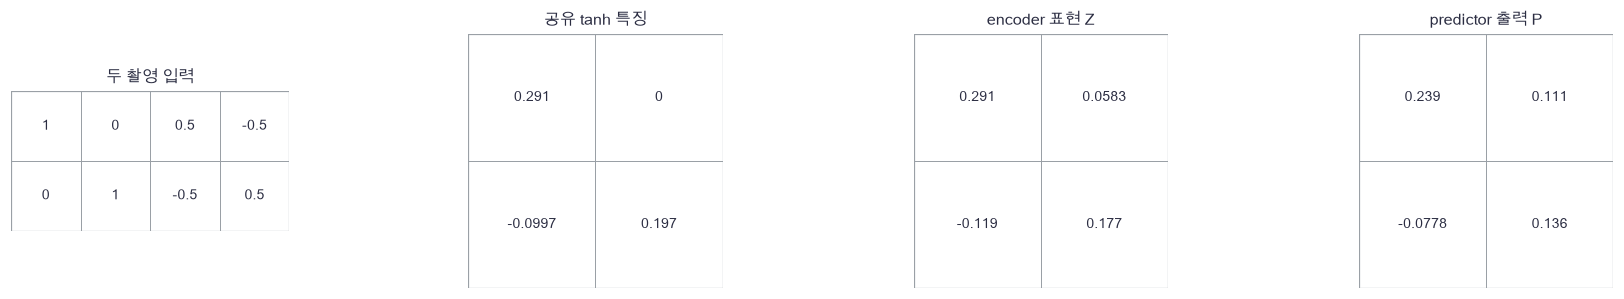

In [10]:
plot_panels([demo_x,demo_h,demo_z,demo_pred],['두 촬영 입력','공유 tanh 특징','encoder 표현 Z','predictor 출력 P'])

🔍 **확인** · online의 세 화살표 모두 학습됩니다. teacher 쪽에도 같은 수치 연산은 있지만 optimizer의 backward 경로가 없습니다.

In [11]:
def init_encoder(seed=390,hidden=8,out=3):
    """4→H→D tanh 표현기. 마지막 출력은 정규화 전 실수입니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.3,(4,hidden)),'b':np.zeros(hidden),
            'V':rng.normal(0,.3,(hidden,out)),'c':np.zeros(out)}

In [12]:
def encode(X,p):
    """H=tanh(XW+b), Z=HV+c. X:(N,4) → Z:(N,D), cache."""
    H=np.tanh(X@p['W']+p['b'])
    return H@p['V']+p['c'],(X,H)

In [13]:
def encode_backward(dZ,cache,p):
    """공유 표현기 모든 파라미터와 연속 입력의 미분입니다."""
    X,H=cache
    dU=(dZ@p['V'].T)*(1-H**2)
    grads={'V':H.T@dZ,'c':dZ.sum(axis=0),'W':X.T@dU,'b':dU.sum(axis=0)}
    return grads,dU@p['W'].T

In [14]:
def init_online(seed=400,hidden=8,out=3):
    """encoder에 선형 predictor Q,d를 붙입니다. target에는 Q,d가 없습니다."""
    p=init_encoder(seed,hidden,out)
    p['Q']=np.eye(out)+np.random.default_rng(seed+1).normal(0,.1,(out,out))
    p['d']=np.zeros(out)
    return p

In [15]:
def online_forward(X,p):
    """online encoder와 predictor를 연결합니다. → 예측:(N,D), cache."""
    Z,cache=encode(X,p)
    return Z@p['Q']+p['d'],(Z,cache)

In [16]:
def online_backward(dP,cache,p):
    """predictor와 encoder의 모든 학습 배열·입력에 대한 미분입니다."""
    Z,encoder_cache=cache
    grads,dX=encode_backward(dP@p['Q'].T,encoder_cache,p)
    grads['Q']=Z.T@dP
    grads['d']=dP.sum(axis=0)
    return grads,dX

In [17]:
def target_pair(views,target):
    """[A,B] 입력에 대응하는 target [B,A] 표현을 만들어 복사합니다."""
    # 쓰는 것: encode (2절)
    half=len(views)//2
    other=np.concatenate([views[half:],views[:half]],axis=0)
    T,_=encode(other,target)
    return T.copy()

In [18]:
# 쓰는 것: alignment (1절) · init_online (2절)
probe=init_online(407,hidden=3,out=2)
probe_x=np.random.default_rng(408).normal(size=(4,4))
probe_target={k:probe[k].copy() for k in ['W','b','V','c']}
frozen_target=target_pair(probe_x,probe_target)
probe_p,probe_cache=online_forward(probe_x,probe)
_,probe_dP=alignment(probe_p,frozen_target)
analytic,analytic_x=online_backward(probe_dP,probe_cache,probe)

In [19]:
def frozen_objective():
    """이번 step의 타깃을 고정한 online 목적입니다."""
    # 쓰는 것: alignment (1절) · online_forward (2절)
    P,_=online_forward(probe_x,probe)
    return alignment(P,frozen_target)[0]

In [20]:
errors=[]
for name in probe:
    numeric=numerical_gradient(frozen_objective,probe[name])
    np.testing.assert_allclose(analytic[name],numeric,atol=2e-7,rtol=3e-5)  # 검산: predictor 포함 모든 online 파라미터
    errors.append(rel_error(analytic[name],numeric))
numeric_x=numerical_gradient(frozen_objective,probe_x)
np.testing.assert_allclose(analytic_x,numeric_x,atol=2e-7,rtol=3e-5)  # 검산: 고정 타깃에서 online 입력 전체
for name in probe_target:
    np.testing.assert_allclose(numerical_gradient(frozen_objective,probe_target[name]),0.)  # 검산: 고정 목적은 teacher 배열을 다시 읽지 않음
print('고정 타깃의 전체 미분 최대 상대오차',max(errors+[rel_error(analytic_x,numeric_x)]))

고정 타깃의 전체 미분 최대 상대오차 1.1066969747403358e-09


### ✏️ 연습 2 · 예측기 가중치 미분

P=ZQ+d에서 상류 G를 받아 predictor 가중치 기울기를 만드세요.

In [21]:
def exercise_predictor_grad(Z,G):
    """P=ZQ+d에서 상류 G를 받아 predictor 가중치 기울기를 만드세요."""

    ### 구현할 내용: P=ZQ+d에서 상류 G를 받아 predictor 가중치 기울기를 만드세요.
    raise NotImplementedError
    return dQ

In [22]:
def check_predictor_grad(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.],[3.,4.]]),np.array([[1.,0.],[0.,2.]])),[[1.,6.],[2.,8.]])  # 검산: 모든 관측 기여 합
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_predictor_grad,exercise_predictor_grad,hint="P=ZQ+d에서 상류 G를 받아 predictor 가중치 기울기를 만드세요.")

☐ exercise_predictor_grad: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: P=ZQ+d에서 상류 G를 받아 predictor 가중치 기울기를 만드세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dQ = Z.T@G
```

</details>

## 🔑 3. 학생을 갱신한 뒤 교사를 천천히 옮깁니다

**이 절에서 가져갈 것:** EMA의 순서·대상·양 끝값을 정확히 구현합니다.

학생이 한 번 배운 뒤 교사의 상태를 조금 옮깁니다. 교사는 정답 라벨을 얻는 것이 아니라 학생 encoder의 과거 값을 섞습니다.

> **용어** · **지수 이동 평균(EMA)**은 최근 값에 일정 비율을 주고 과거 평균을 남기는 갱신입니다. momentum m은 여기서 **남길 교사의 비율**입니다.

$$\theta_{t+1}=\operatorname{Adam}(\theta_t,\nabla_\theta L_t),\qquad
\xi_{t+1}=m\xi_t+(1-m)\theta^{enc}_{t+1}.$$

$t$번째 타깃은 갱신 전 $\xi_t$로 계산합니다. 먼저 online encoder와 predictor를 optimizer로 바꾸고 그다음 encoder만 EMA합니다. m=0이면 새 encoder를 바로 복사하고 m=1이면 초기 teacher를 고정합니다. predictor Q,d는 teacher에 없으므로 EMA하지 않습니다. stop-gradient와 EMA는 별개 규칙입니다.

In [23]:
old_teacher=np.array([[0.,2.]])
new_student=np.array([[2.,4.]])
ema_cases=np.concatenate([m*old_teacher+(1-m)*new_student for m in [0.,.9,1.]],axis=0)

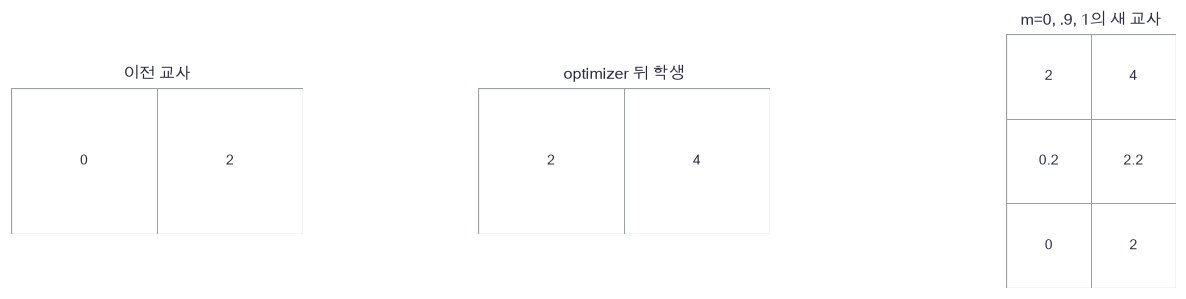

In [24]:
plot_panels([old_teacher,new_student,ema_cases],['이전 교사','optimizer 뒤 학생','m=0, .9, 1의 새 교사'])

🔍 **확인** · m=.9는 새 학생 쪽으로10% 이동합니다. EMA를 optimizer 앞에서 하면 이전 학생을 섞는 다른 알고리즘이 됩니다.

In [25]:
def ema_update(target,online,momentum):
    """optimizer 갱신 뒤 encoder만 EMA합니다. target 사전의 키만 사용합니다."""
    for key in target:
        target[key]=momentum*target[key]+(1-momentum)*online[key]

In [26]:
def adam_step(p,g,m,v,step,lr=.01):
    """Adam 모멘트·bias 보정을 적용합니다."""
    for k in p:
        m[k]=.9*m[k]+.1*g[k]
        v[k]=.999*v[k]+.001*g[k]**2
        p[k]-=lr*(m[k]/(1-.9**step))/(np.sqrt(v[k]/(1-.999**step))+1e-8)

In [27]:
teacher={'W':np.array([[0.,2.]])}
student={'W':np.array([[2.,4.]]),'Q':np.eye(2)}
ema_update(teacher,student,.9)
np.testing.assert_allclose(teacher['W'],[[.2,2.2]])  # 검산: .9*old+.1*new
assert set(teacher)=={'W'}, 'teacher에는 predictor가 추가되지 않아야 합니다'
for momentum,expected in [(0.,student['W']),(1.,np.array([[0.,2.]]))]:
    trial={'W':np.array([[0.,2.]])}
    ema_update(trial,student,momentum)
    np.testing.assert_allclose(trial['W'],expected)  # 검산: m=0 복사와 m=1 고정
print('EMA 순서의 대상·비율·양 끝값을 확인했습니다.')

EMA 순서의 대상·비율·양 끝값을 확인했습니다.


In [28]:
# 쓰는 것: analytic (2절) · probe (2절) · probe_target (2절)
online_step={k:a.copy() for k,a in probe.items()}
teacher_step={k:a.copy() for k,a in probe_target.items()}
old_target={k:a.copy() for k,a in teacher_step.items()}
moment1={k:np.zeros_like(a) for k,a in online_step.items()}
moment2={k:np.zeros_like(a) for k,a in online_step.items()}
adam_step(online_step,analytic,moment1,moment2,1)
for name in teacher_step:
    np.testing.assert_array_equal(teacher_step[name],old_target[name])  # 검산: optimizer는 teacher를 건드리지 않음
ema_update(teacher_step,online_step,.9)
for name in teacher_step:
    np.testing.assert_allclose(teacher_step[name],.9*old_target[name]+.1*online_step[name])  # 검산: 갱신 뒤 online을 EMA
print('online optimizer와 target EMA가 별도임을 확인했습니다.')

online optimizer와 target EMA가 별도임을 확인했습니다.


### ✏️ 연습 3 · 교사 비율로 EMA하기

남길 교사의 비율 m으로 새로운 타깃 배열을 계산하세요.

In [29]:
def exercise_ema(old,new,m):
    """남길 교사의 비율 m으로 새로운 타깃 배열을 계산하세요."""

    ### 구현할 내용: 남길 교사의 비율 m으로 새로운 타깃 배열을 계산하세요.
    raise NotImplementedError
    return target

In [30]:
def check_ema(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,10.]),np.array([4.,2.]),.75),[1.,8.])  # 검산: .75old+.25new
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_ema,exercise_ema,hint="남길 교사의 비율 m으로 새로운 타깃 배열을 계산하세요.")

☐ exercise_ema: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 남길 교사의 비율 m으로 새로운 타깃 배열을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = m*old+(1-m)*new
```

</details>

## 🔑 4. 손실이 작아도 모든 과일이 같아질 수 있습니다

**이 절에서 가져갈 것:** 예측 목적과 샘플 구분 통계를 별도로 검사합니다.

학생과 교사가 모든 과일에 같은 특징을 내면 서로 맞히기는 쉽습니다. 그러나 품종을 구분하는 정보는 사라집니다.

> **용어** · **붕괴(collapse)**는 관측이 달라도 표현이 거의 같아지는 것입니다. **특징 분산**은 관측 축에서 각 차원이 변하는 정도입니다. 이 절은 분모 N인 모집단식 분산을 진단에 씁니다.

$$\mu_d=N^{-1}\sum_i Z_{id},\quad v_d=N^{-1}\sum_i(Z_{id}-\mu_d)^2.$$

상수 표현 Z=c의 분산은0입니다. 같은 상수 P=T이면 정규화 뒤에도 일치하므로 alignment 손실과 dP도0입니다. 반대로 분산이 있다고 품종 정보가 보장되지는 않습니다. 배경만 표현해도 분산이 생깁니다. 평균·분산·다른 샘플 거리·독립 label probe를 함께 읽습니다. 이 작은 모델에는 BYOL 원논문의 이미지 encoder·projection MLP·배치 정규화가 없으므로 EMA만으로 붕괴를 피한다고 주장하지 않습니다.

In [31]:
constant=np.ones((3,2))
separate=np.array([[-1.,0.],[0.,1.],[1.,0.]])
statistics=np.array([[constant.mean(),constant.var(axis=0).mean()],
                     [separate.mean(),separate.var(axis=0).mean()]])

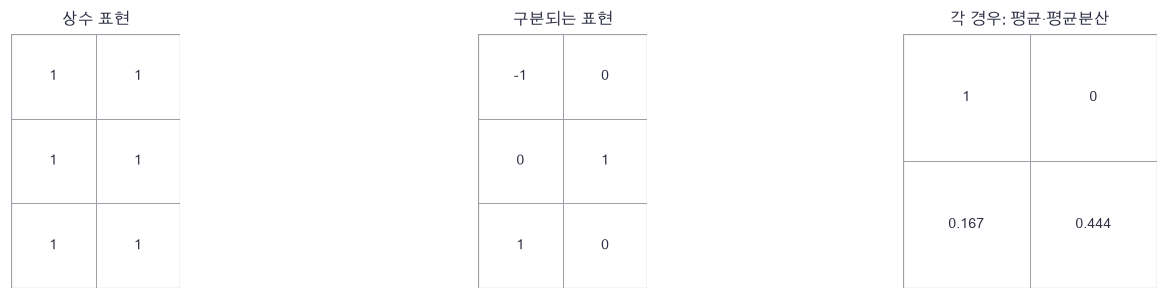

In [32]:
plot_panels([constant,separate,statistics],['상수 표현','구분되는 표현','각 경우: 평균·평균분산'])

🔍 **확인** · 평균이0이어도 영벡터로 모두 같으면 붕괴입니다. 분산 검사는 필요하지만 어떤 정보를 표현하는지는 별도의 평가가 필요합니다.

In [33]:
# 쓰는 것: alignment (1절)
constant_loss,constant_grad=alignment(constant,constant)
np.testing.assert_allclose(constant_loss,0.)  # 검산: 같은 상수의 예측 손실0
np.testing.assert_allclose(constant_grad,0.)  # 검산: 같은 상수의 학생 기울기0
np.testing.assert_allclose(constant.var(axis=0),0.)  # 검산: 샘플 구분 분산0
shifted=separate+7.
np.testing.assert_allclose(shifted.var(axis=0),separate.var(axis=0))  # 검산: 평균 이동은 분산을 바꾸지 않음
print('상수 해와 분산의 의미를 확인했습니다.')

상수 해와 분산의 의미를 확인했습니다.


### ✏️ 연습 4 · 특징별 관측 분산

관측 축으로 특징별 모집단식 분산 (D,)를 반환하세요.

In [34]:
def exercise_feature_variance(Z):
    """관측 축으로 특징별 모집단식 분산 (D,)를 반환하세요."""
    centered = Z-Z.mean(axis=0,keepdims=True)
    ### 구현할 내용: 관측 축으로 특징별 모집단식 분산 (D,)를 반환하세요.
    raise NotImplementedError
    return variance

In [35]:
def check_feature_variance(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.],[3.,2.]])),[1.,0.])  # 검산: 첫 특징만 변화
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_feature_variance,exercise_feature_variance,hint="관측 축으로 특징별 모집단식 분산 (D,)를 반환하세요.")

☐ exercise_feature_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 관측 축으로 특징별 모집단식 분산 (D,)를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
variance = (centered**2).mean(axis=0)
```

</details>

## 🔑 5. 교사 속도별로 실제 학습하고 독립 평가합니다

**이 절에서 가져갈 것:** 같은 예산에서 교사 속도를 바꾸고 목적·표현·probe 결과를 분리합니다.

39번과 같은 세 품종 과일 상황을 쓰되 이번에는 음성 후보 없이 다른 뷰의 타깃을 맞힙니다. 입력 앞 두 열은 품종 상태, 뒤 두 열은 독립 배경이며 두 뷰는 배경만 재추출합니다.

고정 계획: train512/valid64/test256, seed401/402/403. online 초기400, teacher는 encoder 복사, m=0/.9/.99/1의 네 조건. 모든 조건은 같은 배치·뷰 난수404, B32, 300갱신, Adam lr.005입니다. Adam m=.9m+.1g, v=.999v+.001g²를 bias 보정합니다. validation 뷰 seed405는 고정하며 경과만 관찰합니다. label은 표현 학습에 사용하지 않습니다. 평가 후 조건·스텝을 바꾸지 않습니다.

품종 평가에서는 **online encoder 출력 Z를 정규화하고 predictor를 버립니다**. 초기와 네 학습 모델 각각에서 encoder를 동결하고, train 라벨로 3클래스 선형 probe만0초기값·300전배치 SGD·lr.15로 학습합니다. CE의 logit 기울기는 `(softmax-onehot)/N`, 가중치 미분은 `U.T@G`입니다. test 정확도 분모256, 표현 평균분산은 관측 축, 다른 샘플 거리는 test 순서를 한 칸 민 쌍의 평균 제곱거리입니다. 이 거리에는 같은 품종 쌍도 포함됩니다. 한 seed의 결과로 일반적인 교사 속도 순위를 보장하지 않습니다.

> **코드** · `choice(...,replace=False)`는 배치 원본의 비복원추출입니다. `np.roll(U,1,axis=0)`은 평가 쌍을 정할 때 행을 한 칸 순환 이동합니다. list·dict 컴프리헨션은 같은 절차를 각 조건·배열에 적용합니다.

In [36]:
preview_x=np.array([[1.,0.,1.,-1.],[-.5,.866,-1.,1.],[-.5,-.866,.5,.5]])
preview_pair=preview_x.copy()
preview_pair[:,2:]=np.array([[0.,.5],[.5,0.],[-.5,-.5]])
plan=np.array([[512,401],[64,402],[256,403]])

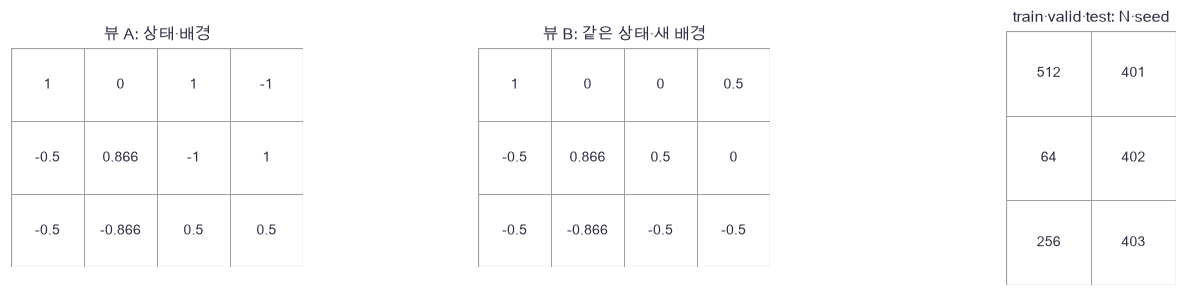

In [37]:
plot_panels([preview_x,preview_pair,plan],['뷰 A: 상태·배경','뷰 B: 같은 상태·새 배경','train·valid·test: N·seed'])

🔍 **확인** · 교사는 원래 정답을 가진 모델이 아니라 같은 초기 학생에서 출발합니다. validation 손실이 낮다는 것만으로 품종 정보가 남았다고 판단하지 않습니다.

In [38]:
def make_data(n,seed):
    """세 품종의 상태 2차원과 독립 배경 2차원 합성 관측을 만듭니다."""
    rng=np.random.default_rng(seed)
    y=rng.integers(0,3,n)
    angles=2*np.pi*y/3
    state=np.column_stack([np.cos(angles),np.sin(angles)])+.2*rng.normal(size=(n,2))
    nuisance=rng.normal(size=(n,2))
    return np.concatenate([state,nuisance],axis=1),y

In [39]:
def two_views(X,rng):
    """상태는 고정하고 두 뷰의 배경을 독립 재추출합니다. → (2N,4)."""
    A=X.copy()
    B=X.copy()
    A[:,2:]=rng.normal(size=(len(X),2))
    B[:,2:]=rng.normal(size=(len(X),2))
    return np.concatenate([A,B],axis=0)

In [40]:
def train_teacher(X,valid_views,initial,momentum):
    """300회 online Adam 후 target EMA, 고정 valid 쌍을 기록합니다."""
    # 쓰는 것: adam_step (3절) · alignment (1절) · ema_update (3절) · online_backward (2절) · online_forward (2절) · target_pair (2절)
    # 1. predictor 없는 target을 같은 encoder 값에서 시작합니다.
    online={k:a.copy() for k,a in initial.items()}
    target={k:initial[k].copy() for k in ['W','b','V','c']}
    m={k:np.zeros_like(a) for k,a in online.items()}
    v={k:np.zeros_like(a) for k,a in online.items()}
    rng=np.random.default_rng(404)
    history=[]
    # 2. 이번 target을 고정하고 online만 미분한 뒤 EMA합니다.
    for step in range(1,301):
        idx=rng.choice(len(X),32,replace=False)
        views=two_views(X[idx],rng)
        T=target_pair(views,target)
        P,cache=online_forward(views,online)
        loss,dP=alignment(P,T)
        grads,_=online_backward(dP,cache,online)
        adam_step(online,grads,m,v,step,lr=.005)
        ema_update(target,online,momentum)
        if step%30==0:
            P,_=online_forward(valid_views,online)
            T=target_pair(valid_views,target)
            history.append([step,alignment(P,T)[0]])
    return online,target,np.array(history)

In [41]:
def multiclass_loss(logits,y):
    """안정적인 표본 평균 CE와 logit 미분. (N,C), (N,) → scalar,(N,C)."""
    shifted=logits-logits.max(axis=1,keepdims=True)
    expS=np.exp(shifted)
    P=expS/expS.sum(axis=1,keepdims=True)
    loss=np.mean(np.log(expS.sum(axis=1))-shifted[np.arange(len(y)),y])
    G=P.copy()
    G[np.arange(len(y)),y]-=1
    return loss,G/len(y)

In [42]:
def fit_probe(features,y):
    """고정 표현 위의 선형 3클래스 probe만 300회 전배치 SGD 학습합니다."""
    W=np.zeros((features.shape[1],3))
    b=np.zeros(3)
    for step in range(300):
        loss,G=multiclass_loss(features@W+b,y)
        W-=.15*features.T@G
        b-=.15*G.sum(axis=0)
    return W,b

In [43]:
# 쓰는 것: init_online (2절) · make_data (5절) · two_views (5절)
train_x,train_y=make_data(512,401)
valid_x,valid_y=make_data(64,402)
test_x,test_y=make_data(256,403)
valid_views=two_views(valid_x,np.random.default_rng(405))
initial=init_online(400)
momenta=[0.,.9,.99,1.]
models=[]
histories=[]
for momentum in momenta:
    online,target,history=train_teacher(train_x,valid_views,initial,momentum)
    models.append((online,target))
    histories.append(history)
print('online 파라미터',sum(a.size for a in initial.values()),'· teacher encoder',sum(initial[k].size for k in ['W','b','V','c']))

online 파라미터 79 · teacher encoder 67


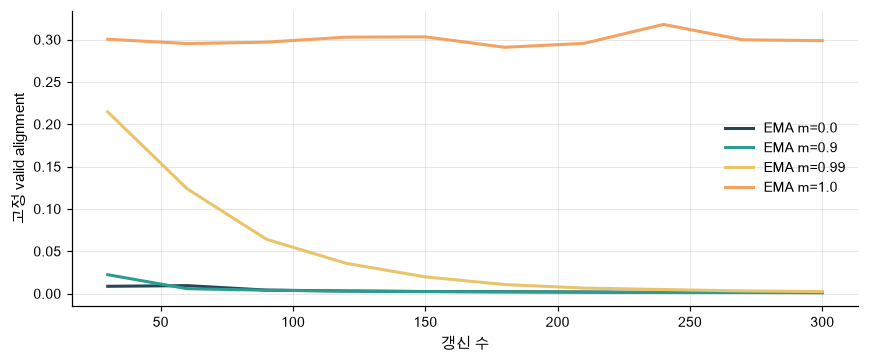

In [44]:
plot_curves(histories,[f'EMA m={m}' for m in momenta],'고정 valid alignment')

In [45]:
# 쓰는 것: encode (2절) · normalize_rows (1절)
report=[]
representations=[]
for p in [initial]+[pair[0] for pair in models]:
    frozen={k:a.copy() for k,a in p.items()}
    train_z,_=encode(train_x,p)
    train_u,_=normalize_rows(train_z)
    test_z,_=encode(test_x,p)
    test_u,_=normalize_rows(test_z)
    Wq,bq=fit_probe(train_u,train_y)
    accuracy=np.mean((test_u@Wq+bq).argmax(axis=1)==test_y)
    distinct_distance=((test_u-np.roll(test_u,1,axis=0))**2).sum(axis=1).mean()
    report.append([accuracy,test_u.mean(),test_u.var(axis=0).mean(),distinct_distance])
    representations.append(test_u)
    for key in p:
        np.testing.assert_array_equal(p[key],frozen[key])  # 검산: probe 중 encoder·predictor 불변
report=np.array(report)
print('행: 초기,m=0,.9,.99,1 · 열: test정확도, 평균, 평균분산, 다른샘플거리',np.round(report,4))

행: 초기,m=0,.9,.99,1 · 열: test정확도, 평균, 평균분산, 다른샘플거리 [[ 0.793  -0.023   0.3282  1.9464]
 [ 0.9961  0.0051  0.323   1.9659]
 [ 1.      0.0137  0.3241  1.9737]
 [ 0.9961 -0.0358  0.3267  1.9605]
 [ 0.9883 -0.047   0.3193  1.9212]]


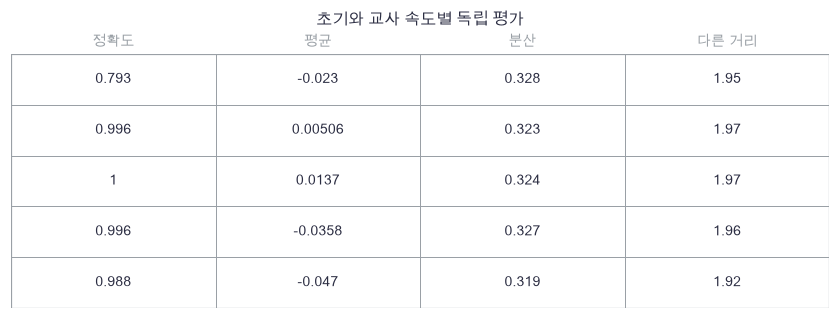

In [46]:
plot_panels([report],['초기와 교사 속도별 독립 평가'],[['정확도','평균','분산','다른 거리']])

In [47]:
# 쓰는 것: init_online (2절) · initial (5절) · models (5절)
for key in ['W','b','V','c']:
    np.testing.assert_array_equal(models[-1][1][key],initial[key])  # 검산: m=1 teacher는 끝까지 초기 encoder
    np.testing.assert_allclose(models[0][1][key],models[0][0][key])  # 검산: m=0 teacher는 마지막 online과 같음
np.testing.assert_array_equal(initial['W'],init_online(400)['W'])  # 검산: 초기 모델 사본 보존
print('실제 학습에서도 m=0·1의 규약을 확인했습니다.')

실제 학습에서도 m=0·1의 규약을 확인했습니다.


🔍 **확인** · 위 출력은 이 작은 구조와 합성 변형에서 실제로 얻은 결과입니다. 각 조건의 target도 달라지므로 서로 다른 조건의 작은 alignment를 곧바로 성능 순위로 읽지 마세요. 초기 모델과 비교한 probe·분산·샘플 거리를 함께 해석하세요. 41번은 분산과 공분산을 목적에 직접 넣어 붕괴와 중복 특징을 다룹니다.

### ✏️ 연습 5 · 사용할 encoder 출력을 고르기

평가에 사용할 encoder 출력만 계산하세요. predictor Q,d를 적용하지 않습니다.

In [48]:
def exercise_drop_predictor(X,W,bias,V,c):
    """평가에 사용할 encoder 출력만 계산하세요. predictor Q,d를 적용하지 않습니다."""

    ### 구현할 내용: 평가에 사용할 encoder 출력만 계산하세요. predictor Q,d를 적용하지 않습니다.
    raise NotImplementedError
    return Z

In [49]:
def check_drop_predictor(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.zeros((2,1)),np.ones((1,2)),np.zeros(2),np.ones((2,3)),np.array([1.,2.,3.])),[[1.,2.,3.],[1.,2.,3.]])  # 검산: predictor 없이 encoder의 c만 남음
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_drop_predictor,exercise_drop_predictor,hint="평가에 사용할 encoder 출력만 계산하세요. predictor Q,d를 적용하지 않습니다.")

☐ exercise_drop_predictor: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 평가에 사용할 encoder 출력만 계산하세요. predictor Q,d를 적용하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
Z = np.tanh(X@W+bias)@V+c
```

</details>

## ✏️ 끝 연습 · 타깃과 갱신의 경계를 바꿔 봅니다

### ✏️ 연습 A · 양방향 타깃의 순서

encoder 출력이 A 다음 B이면 대응할 타깃은 B 다음 A로 바꾸세요.

In [50]:
def exercise_swap_views(Z):
    """encoder 출력이 A 다음 B이면 대응할 타깃은 B 다음 A로 바꾸세요."""
    B = len(Z)//2
    ### 구현할 내용: encoder 출력이 A 다음 B이면 대응할 타깃은 B 다음 A로 바꾸세요.
    raise NotImplementedError
    return target

In [51]:
def check_swap_views(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[1.],[2.],[10.],[20.]])),[[10.],[20.],[1.],[2.]])  # 검산: A0,A1에 B0,B1 대응
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_swap_views,exercise_swap_views,hint="encoder 출력이 A 다음 B이면 대응할 타깃은 B 다음 A로 바꾸세요.")

☐ exercise_swap_views: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: encoder 출력이 A 다음 B이면 대응할 타깃은 B 다음 A로 바꾸세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = np.concatenate([Z[B:],Z[:B]],axis=0)
```

</details>

### ✏️ 연습 B · 두 번의 EMA를 펼치기

첫 새 학생 a, 둘째 새 학생 beta에 대한 두 번의 EMA를 닫힌 식으로 계산하세요.

In [52]:
def exercise_ema_two(old,a,beta,m):
    """첫 새 학생 a, 둘째 새 학생 beta에 대한 두 번의 EMA를 닫힌 식으로 계산하세요."""

    ### 구현할 내용: 첫 새 학생 a, 둘째 새 학생 beta에 대한 두 번의 EMA를 닫힌 식으로 계산하세요.
    raise NotImplementedError
    return value

In [53]:
def check_ema_two(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([0.]),np.array([2.]),np.array([4.]),.5),[2.5])  # 검산: 0→1→2.5
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_ema_two,exercise_ema_two,hint="첫 새 학생 a, 둘째 새 학생 beta에 대한 두 번의 EMA를 닫힌 식으로 계산하세요.")

☐ exercise_ema_two: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 첫 새 학생 a, 둘째 새 학생 beta에 대한 두 번의 EMA를 닫힌 식으로 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = m*m*old+m*(1-m)*a+(1-m)*beta
```

</details>

### ✏️ 연습 C · 독립 타깃 사본 만들기

타깃 값의 독립 사본을 반환하세요. 복사만으로 자동 미분이 차단되는 것은 아니며 이 구현은 backward를 호출하지 않습니다.

In [54]:
def exercise_frozen_copy(T):
    """타깃 값의 독립 사본을 반환하세요. 복사만으로 자동 미분이 차단되는 것은 아니며 이 구현은 backward를 호출하지 않습니다."""

    ### 구현할 내용: 타깃 값의 독립 사본을 반환하세요. 복사만으로 자동 미분이 차단되는 것은 아니며 이 구현은 backward를 호출하지 않습니다.
    raise NotImplementedError
    return target

In [55]:
def check_frozen_copy(candidate):
    """작은 독립 기준값과 비교합니다."""
    original=np.array([[1.,2.]])
    copy=candidate(original)
    copy[0,0]=99.
    np.testing.assert_array_equal(original,[[1.,2.]])  # 검산: 사본 수정은 원본 불변
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_frozen_copy,exercise_frozen_copy,hint="타깃 값의 독립 사본을 반환하세요. 복사만으로 자동 미분이 차단되는 것은 아니며 이 구현은 backward를 호출하지 않습니다.")

☐ exercise_frozen_copy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 타깃 값의 독립 사본을 반환하세요. 복사만으로 자동 미분이 차단되는 것은 아니며 이 구현은 backward를 호출하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = T.copy()
```

</details>

### ✏️ 연습 D · 차원이 바뀌어도 관측 평균 유지

정규화가 끝난 P,T에 대해 D로 나누지 않고 관측별 반 제곱거리를 평균하세요.

In [56]:
def exercise_loss_dimension(P,T):
    """정규화가 끝난 P,T에 대해 D로 나누지 않고 관측별 반 제곱거리를 평균하세요."""

    ### 구현할 내용: 정규화가 끝난 P,T에 대해 D로 나누지 않고 관측별 반 제곱거리를 평균하세요.
    raise NotImplementedError
    return value

In [57]:
def check_loss_dimension(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.ones((2,3)),np.zeros((2,3))),1.5)  # 검산: 세 좌표 제곱합의 반
    np.testing.assert_allclose(candidate(np.ones((1,2)),np.zeros((1,2))),1.)  # 검산: N=1,D=2
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_loss_dimension,exercise_loss_dimension,hint="정규화가 끝난 P,T에 대해 D로 나누지 않고 관측별 반 제곱거리를 평균하세요.")

☐ exercise_loss_dimension: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정규화가 끝난 P,T에 대해 D로 나누지 않고 관측별 반 제곱거리를 평균하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = .5*((P-T)**2).sum(axis=1).mean()
```

</details>

### ✏️ 준비도 질문

- **설명:** stop-gradient와 EMA는 각각 무엇을 바꾸나요? predictor는 어느 모델에 있나요? → 1–3절
- **수식:** 양방향 alignment의 분모와 정규화 미분, EMA의 m=0·1을 쓸 수 있나요? → 1–3절
- **구현:** 이번 타깃을 고정한 전체 미분 검산과 Adam→EMA 순서 검산을 다시 실행할 수 있나요? → 2·3절
- **변형 검산:** D·B·교사 비율을 바꾸어 상수 해·동결 평가·독립 사본을 확인할 수 있나요? → 4·5절, 연습 A–D

### 📎 원전과 범위

[BYOL 원논문, Grill et al., 2020](https://arxiv.org/abs/2006.07733)은 online이 다른 뷰의 target 표현을 예측하고 target을 online의 이동 평균으로 갱신하는 방법을 제안합니다. 여기서는 작은 tanh encoder와 선형 predictor로 기울기 경로를 학습하며 원논문의 전체 구조나 이미지 benchmark 성능을 재현하지 않습니다. 41번 분산·공분산 제약과 43번 영역별 표현 타깃 예측으로 이어집니다.